# GNSS pod oblohou: skutečné družice, DOP, terén a výška v Bpv

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gnss_sky_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [GNSS pod oblohou](https://openskylab.space/edu_viz_gnss_sky.html) · [English version](gnss_sky_en.ipynb)

Vizuál ukazuje, jak počet a rozložení družic určují DOP, co udělají překážky a elevační maska a proč je výška z GNSS méně přesná než poloha. Tady spočítáš polohy skutečných družic GPS, Galileo, GLONASS a BeiDou z aktuálních drah, skutečný horizont v údolí Vltavy z modelu terénu ČÚZK a převod elipsoidické výšky na výšku v Bpv z bodů bodového pole.

**Cíl:** nakreslit skutečnou oblohu GNSS nad Suchdolem, spočítat HDOP, VDOP a PDOP během dne, posoudit vliv lesa a hlubokého údolí, najít nejbližší referenční stanici CZEPOS a převést výšku z RTK do Bpv.

**Data:** aktuální dráhové elementy (TLE) skupiny GNSS z CelesTrak; DMR 5G (ČÚZK) pro horizont v údolí; stanice sítě CZEPOS a zhušťovací body bodového pole s výškou v Bpv i elipsoidickou výškou ETRS89 ze služby ČÚZK BodovaPole.

**Úkoly:** čtyři. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a dráhy družic

In [1]:
%pip install -q sgp4 rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
from datetime import datetime, timedelta, timezone
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from sgp4.api import Satrec, jday

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

for attempt in range(6):                     # CelesTrak občas spojení odmítne; zkusíme to znovu
    try:
        r = requests.get("https://celestrak.org/NORAD/elements/gp.php", params={"GROUP": "gnss", "FORMAT": "tle"}, timeout=60)
        if r.ok and r.text.startswith(("GPS", "COSMOS", "BEIDOU", "GSAT", "INMARSAT", "QZS", "IRNSS", "NVS", "SES")) or r.text.count("\n1 ") > 50:
            break
    except requests.RequestException as e:
        print("CelesTrak:", type(e).__name__, "– zkusím znovu")
    time.sleep(5 * (attempt + 1))
lines = [l.rstrip() for l in r.text.splitlines() if l.strip()]

def system(name):
    if name.startswith("GPS"): return "GPS"
    if name.startswith("GSAT0"): return "Galileo"
    if name.startswith("COSMOS"): return "GLONASS"
    if name.startswith("BEIDOU"): return "BeiDou"
    return None
SATS = [(lines[i].strip(), system(lines[i]), Satrec.twoline2rv(lines[i + 1], lines[i + 2])) for i in range(0, len(lines) - 2, 3)]
SATS = [s for s in SATS if s[1]]
print(pd.Series([s[1] for s in SATS]).value_counts().to_string())

CelesTrak: ConnectionError – zkusím znovu


CelesTrak: ConnectionError – zkusím znovu


BeiDou     53
GPS        32
Galileo    32
GLONASS    26


2026-10-28 23:59 UTC: nad maskou 10° je 41 družic: {'BeiDou': 14, 'Galileo': 11, 'GPS': 8, 'GLONASS': 8}


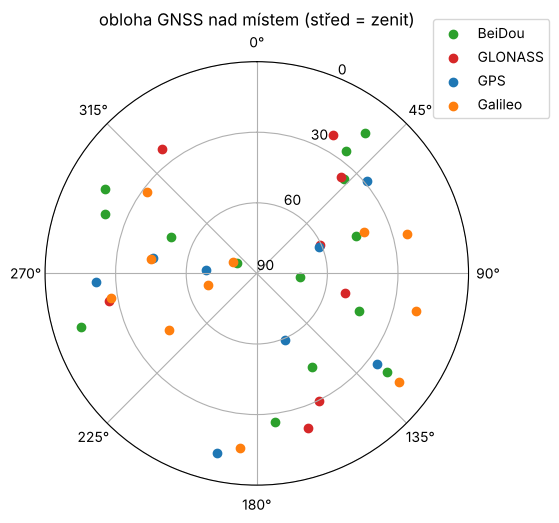

In [3]:
A, F = 6378137.0, 1 / 298.257223563
def ecef(lat, lon, h):
    la, lo = np.radians(lat), np.radians(lon); e2 = F * (2 - F); N = A / np.sqrt(1 - e2 * np.sin(la) ** 2)
    return np.array([(N + h) * np.cos(la) * np.cos(lo), (N + h) * np.cos(la) * np.sin(lo), (N * (1 - e2) + h) * np.sin(la)])

def az_el(t_utc, lat, lon, h=300.0):
    """Azimut a elevace (°) všech družic v čase t_utc pro místo lat, lon, h (elipsoidická výška)."""
    jd, fr = jday(t_utc.year, t_utc.month, t_utc.day, t_utc.hour, t_utc.minute, t_utc.second)
    gmst = np.radians((280.46061837 + 360.98564736629 * (jd + fr - 2451545.0)) % 360)
    R = np.array([[np.cos(gmst), np.sin(gmst), 0], [-np.sin(gmst), np.cos(gmst), 0], [0, 0, 1]])  # TEME → ECEF (bez pohybu pólu)
    la, lo = np.radians(lat), np.radians(lon)
    enu = np.array([[-np.sin(lo), np.cos(lo), 0],
                    [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
                    [np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]])
    site = ecef(lat, lon, h)
    rows = []
    for name, sysname, sat in SATS:
        e, r_, _ = sat.sgp4(jd, fr)
        if e: continue
        d = enu @ (R @ (np.array(r_) * 1000) - site)
        rows.append((name, sysname, np.degrees(np.arctan2(d[0], d[1])) % 360, np.degrees(np.arcsin(d[2] / np.linalg.norm(d)))))
    return pd.DataFrame(rows, columns=["družice", "systém", "az", "el"])

LAT, LON = 50.130, 14.373          # ◀ parametr: místo (kampus v Suchdole)
now = datetime.now(timezone.utc).replace(second=0, microsecond=0)
sky = az_el(now, LAT, LON)
mask = 10                          # ◀ parametr: elevační maska (°)
vis = sky[sky.el > mask]
print(f"{now:%Y-%m-%d %H:%M} UTC: nad maskou {mask}° je {len(vis)} družic:", vis.systém.value_counts().to_dict())
COL = {"GPS": "tab:blue", "Galileo": "tab:orange", "GLONASS": "tab:red", "BeiDou": "tab:green"}
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rlim(90, 0); ax.set_rticks([0, 30, 60, 90])
for s, g in vis.groupby("systém"):
    ax.scatter(np.radians(g.az), g.el, c=COL[s], label=s)
ax.legend(loc="lower left", bbox_to_anchor=(0.9, 0.85)); ax.set_title("obloha GNSS nad místem (střed = zenit)"); plt.show()

## 2. DOP během dne

DOP spočítáme z geometrie: každá družice dá řádek matice G s jednotkovým vektorem směru (východ, sever, nahoru) a jedničkou pro hodiny přijímače (každý systém má vlastní posun hodin). Q = (GᵀG)⁻¹, HDOP = √(Q_EE + Q_NN), VDOP = √Q_UU, PDOP = √(Q_EE + Q_NN + Q_UU).

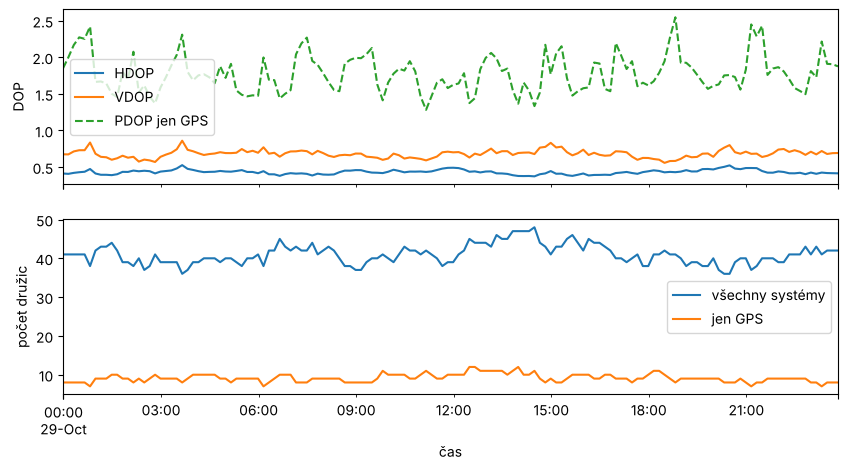

     HDOP  VDOP  PDOP  družic
min  0.37  0.56  0.70    36.0
50%  0.43  0.68  0.80    41.0
max  0.53  0.86  1.01    48.0


In [4]:
def dop(df, systems=("GPS", "Galileo", "GLONASS", "BeiDou")):
    df = df[df.systém.isin(systems)]
    if len(df) < 4 + df.systém.nunique() - 1:
        return np.nan, np.nan, np.nan, len(df)
    az, el = np.radians(df.az.values), np.radians(df.el.values)
    G = np.c_[-np.cos(el) * np.sin(az), -np.cos(el) * np.cos(az), -np.sin(el)]
    G = np.c_[G, pd.get_dummies(df.systém).values.astype(float)]
    Q = np.linalg.inv(G.T @ G)
    return np.sqrt(Q[0, 0] + Q[1, 1]), np.sqrt(Q[2, 2]), np.sqrt(Q[0, 0] + Q[1, 1] + Q[2, 2]), len(df)

def day_series(horizon=lambda az: np.full_like(az, mask, dtype=float), systems=("GPS", "Galileo", "GLONASS", "BeiDou"), lat=LAT, lon=LON, step=10):
    out = []
    for k in range(0, 24 * 60, step):
        tt = now + timedelta(minutes=k)
        s = az_el(tt, lat, lon)
        s = s[s.el > horizon(s.az.values)]
        out.append((tt, *dop(s, systems)))
    return pd.DataFrame(out, columns=["čas", "HDOP", "VDOP", "PDOP", "družic"]).set_index("čas")

open_sky = day_series()
gps_only = day_series(systems=("GPS",))
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
open_sky[["HDOP", "VDOP"]].plot(ax=ax[0]); gps_only[["PDOP"]].rename(columns={"PDOP": "PDOP jen GPS"}).plot(ax=ax[0], ls="--")
open_sky["družic"].plot(ax=ax[1], label="všechny systémy"); gps_only["družic"].plot(ax=ax[1], label="jen GPS"); ax[1].legend()
ax[0].set_ylabel("DOP"); ax[1].set_ylabel("počet družic"); plt.show()
print(open_sky.describe().loc[["min", "50%", "max"]].round(2))

> **✏️ Úkol 1.** Proč je VDOP po celý den větší než HDOP? Vysvětli to tím, kde družice na obloze jsou a kde být nemohou. Kolik družic vidí přijímač se čtyřmi systémy a kolik jen s GPS, a jak se to projeví na PDOP? Nastav masku 20° a pak 5°.

*Tvoje odpověď:* 

## 3. Les na jihu, nebo na severu?

Okraj lesa zakryje oblohu do výšky asi 35° na jedné straně. Dráhy GPS (sklon 55°) a Galilea (56°) nevystoupí nad 55–56° zeměpisné šířky, a proto ve střední Evropě zůstává na severní obloze ve středních výškách místo bez družic. Nízko nad severním obzorem ale vidíme družice, které letí „za pólem“. Která strana lesa vadí víc, proto není samozřejmé a záleží na výšce lesa.

In [5]:
forest_el = 35                         # ◀ parametr: výška okraje lesa nad obzorem (°)
south = lambda az: np.where((az > 90) & (az < 270), forest_el, mask)
north = lambda az: np.where((az < 90) | (az > 270), forest_el, mask)
res = pd.DataFrame({name: day_series(h, step=20).median() for name, h in [("volná obloha", lambda az: np.full_like(az, mask, float)), ("les na jihu", south), ("les na severu", north)]})
res.round(2)

,volná obloha,les na jihu,les na severu
HDOP,0.43,0.68,0.71
VDOP,0.68,0.97,1.06
PDOP,0.81,1.19,1.27
družic,41.00,32.00,27.00


> **✏️ Úkol 2.** Kde je na obloze z kroku 1 „díra“ bez družic a proč? Vyzkoušej forest_el 20°, 35° a 60°: vadí víc les na severu, nebo na jihu? Platí tedy častá rada „na severu je díra, takže les na severu nevadí“? Vysvětli výsledek podle toho, ve kterých výškách nad obzorem je na severu díra a ve kterých družice „za pólem“ (pomůže obrázek z kroku 1 v jiných hodinách). Kde bys postavil základnovou stanici nebo měřil vlícovací bod?

*Tvoje odpověď:* 

## 4. Hluboké údolí: skutečný horizont z DMR 5G

Pro bod u Vltavy v Roztokách spočítáme z modelu terénu výšku horizontu v každém azimutu a podle ní vybereme viditelné družice.

terén v bodě 183.1 m n. m.; horizont 0.3–12.6°


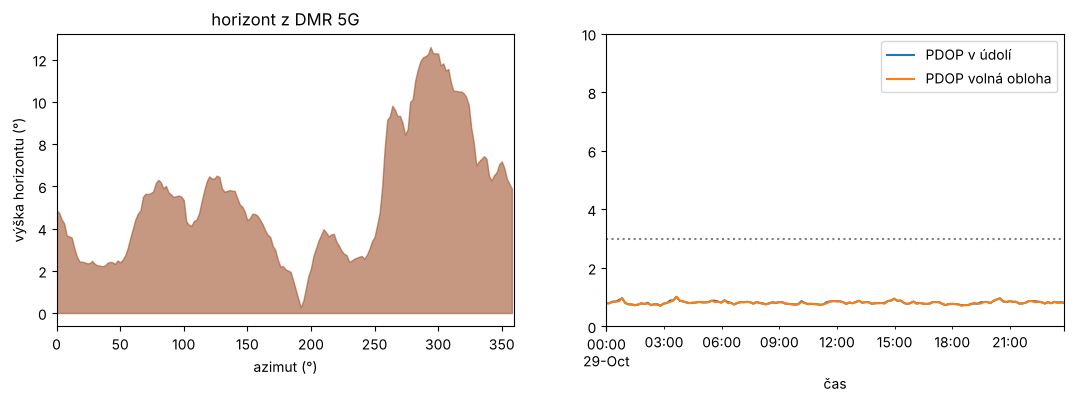

v údolí je PDOP < 3 a aspoň 10 družic 24.0 h z 24 h


In [6]:
VLAT, VLON = 50.1588, 14.3985        # ◀ parametr: bod v údolí (u Vltavy v Roztokách)
R_h = 2500
to_sjtsk = Transformer.from_crs(4326, 5514, always_xy=True)
vx, vy = to_sjtsk.transform(VLON, VLAT)
dem, tr = cuzk_raster("dmr5g", vx - R_h, vy - R_h, vx + R_h, vy + R_h, res=10)
row0, col0 = rasterio.transform.rowcol(tr, vx, vy); z0 = dem[row0, col0] + 1.8      # anténa 1,8 m nad terénem
azs = np.arange(0, 360, 2); dist = np.arange(20, R_h, 10)
hor = []
for a in np.radians(azs):
    xs, ys = vx + dist * np.sin(a), vy + dist * np.cos(a)
    rr, cc = rasterio.transform.rowcol(tr, xs, ys)
    hor.append(np.degrees(np.arctan2(dem[np.array(rr), np.array(cc)] - z0, dist)).max())
hor = np.maximum(np.array(hor), 0)
valley = lambda az: np.maximum(np.interp(az, azs, hor, period=360), mask)
print(f"terén v bodě {dem[row0, col0]:.1f} m n. m.; horizont {hor.min():.1f}–{hor.max():.1f}°")
v_day = day_series(valley, lat=VLAT, lon=VLON, step=10)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].fill_between(azs, 0, hor, color="sienna", alpha=0.6); ax[0].set(xlabel="azimut (°)", ylabel="výška horizontu (°)", xlim=(0, 360), title="horizont z DMR 5G")
v_day.PDOP.plot(ax=ax[1], label="PDOP v údolí"); open_sky.PDOP.plot(ax=ax[1], label="PDOP volná obloha"); ax[1].axhline(3, color="gray", ls=":")
ax[1].set_ylim(0, 10); ax[1].legend(); plt.show()
good = v_day[(v_day.PDOP < 3) & (v_day.družic >= 10)]
print(f"v údolí je PDOP < 3 a aspoň 10 družic {len(good) * 10 / 60:.1f} h z 24 h")

> **✏️ Úkol 3.** Které směry údolí zakrývá nejvíc a proč? Kdy během příštích 24 hodin bys v údolí měřil vlícovací body? Proč model terénu nezachytí všechno, co signál ve skutečnosti blokuje nebo odráží (stromy, budovy, skalní stěny)?

*Tvoje odpověď:* 

## 5. Referenční stanice CZEPOS

Přesnost RTK klesá se vzdáleností od referenční stanice, protože se rozcházejí vlivy ionosféry, troposféry a drah. Výrobci obvykle udávají přesnost ve tvaru 1 cm + 1 ppm (1 mm na každý km).

In [7]:
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/0/query",
                 params={"where": "1=1", "outFields": "NAZEV_BODU,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
cz = pd.DataFrame([f["attributes"] for f in q["features"]])
cz["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin(np.radians(cz.B - LAT) / 2) ** 2 + np.cos(np.radians(LAT)) * np.cos(np.radians(cz.B)) * np.sin(np.radians(cz.L - LON) / 2) ** 2))
cz["RTK horiz. (mm)"] = 10 + 1.0 * cz.km
print(f"stanic CZEPOS: {len(cz)}")
cz.sort_values("km").head(5).round(2)

stanic CZEPOS: 29


,NAZEV_BODU,B,L,HEL,NAZEV_KU,km,RTK horiz. (mm)
16,CPRG,50.13,14.46,356.02,Kobylisy,5.94,15.94
24,GOPE,49.91,14.79,592.60,Ondřejov u Prahy,38.05,48.05
18,CRAK,50.10,13.73,381.87,Rakovník,46.00,56.00
12,CLIT,50.54,14.14,243.28,Litoměřice,48.52,58.52
13,CMBO,50.41,14.91,303.46,Mladá Boleslav,49.24,59.24


## 6. Elipsoidická výška, nebo Bpv?

RTK dává výšku nad elipsoidem GRS80 (ETRS89). Mapy a projekty v Česku používají normální výšku v Bpv. Rozdíl je výšková anomálie ζ = h − H. Vezmeme zhušťovací body bodového pole v okolí, které mají obě výšky.

bodů: 45, ζ = 44.461 až 45.367 m, průměr 44.906 m


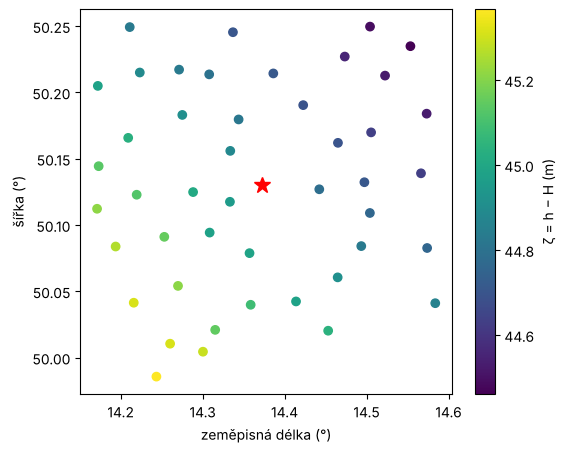

In [8]:
px, py = to_sjtsk.transform(LON, LAT)
half = 15000                       # ◀ parametr: poloviční šířka okolí (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{px - half},{py - half},{px + half},{py + half}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,Y,X,VYSKA,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
pts = pd.DataFrame([f["attributes"] for f in q["features"]])
pts["H_Bpv"] = pd.to_numeric(pts.VYSKA, errors="coerce")
pts = pts.dropna(subset=["H_Bpv", "HEL"])
pts["zeta"] = pts.HEL - pts.H_Bpv
print(f"bodů: {len(pts)}, ζ = {pts.zeta.min():.3f} až {pts.zeta.max():.3f} m, průměr {pts.zeta.mean():.3f} m")
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(pts.L, pts.B, c=pts.zeta, cmap="viridis"); fig.colorbar(sc, label="ζ = h − H (m)")
ax.plot(LON, LAT, "r*", ms=12); ax.set(xlabel="zeměpisná délka (°)", ylabel="šířka (°)"); plt.show()

> **✏️ Úkol 4.** Jaká je výšková anomálie v okolí Suchdola a o kolik se mění na 30 km? Co se stane s modelem terénu nebo s vlícovacími body, když výšky z RTK zapíšeš jako Bpv bez převodu? Proč nestačí odečíst jednu konstantu pro celou republiku a co k převodu použít (model kvazigeoidu, transformační služba ČÚZK)? Jak daleko je nejbližší stanice CZEPOS a jak velkou chybu RTK z toho čekáš?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Dráhové elementy: CelesTrak (T. S. Kelso), skupina GNSS, https://celestrak.org/NORAD/elements/gp.php?GROUP=gnss. Pozor: TLE s modelem SGP4 dávají polohu družice s chybou řádově kilometrů; pro plánování DOP to stačí, pro výpočet polohy přijímače ne (ten používá vysílané efemeridy).
- Bodová pole a stanice CZEPOS: © ČÚZK, služba https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0).
- DMR 5G: © ČÚZK, CC BY 4.0, https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- Vallado, D. A., Crawford, P., Hujsak, R., Kelso, T. S. (2006). Revisiting Spacetrack Report #3. AIAA 2006-6753 (model SGP4, knihovna `sgp4`).
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (DOP, víc systémů, RTK).

### Jak citovat

OpenSkyLab (2026). GNSS pod oblohou: skutečné družice, DOP, terén a výška v Bpv [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gnss_sky_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*